## KNN: ImageNet

Load default ResNet50 trained on ImageNet and predict prototypes for several classes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob, os, pickle, cv2
from sklearn.metrics import label_ranking_average_precision_score as lrap
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D

In [2]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-04-11 15:01:23.142327: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-11 15:01:23.696524: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
IMAGES_PATH   = '../data/Unsplash/images/'
CONCEPTS_PATH = '../data/Unsplash/concepts_broden/'
img_height = img_width = 224

### Load Test Images

In [4]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [5]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


2024-04-11 15:01:23.781234: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [6]:
# Keep a copy of unpreprocessed images
test_set_orig = test_set

In [7]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [8]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


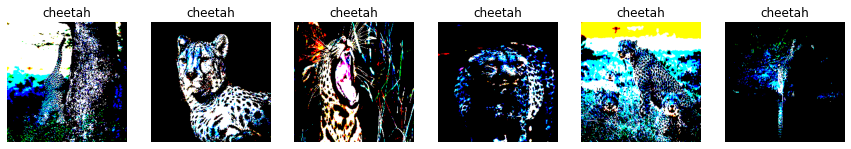

In [9]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Prototype Images

In [10]:
concepts = [c.split('/')[-1] for c in sorted(glob.glob(CONCEPTS_PATH + '*'))]
concepts

['chequered', 'dotted', 'striped']

In [11]:
concept_set = tf.keras.utils.image_dataset_from_directory(
    CONCEPTS_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 90 files belonging to 3 classes.


In [12]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
concept_set = concept_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [13]:
# Get concept label vector from tf.Dataset
y_true_con = np.asarray([lab.numpy() for _, lab in concept_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


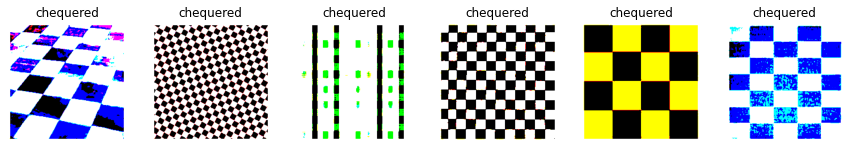

In [14]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in concept_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(concepts[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load Random Images

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

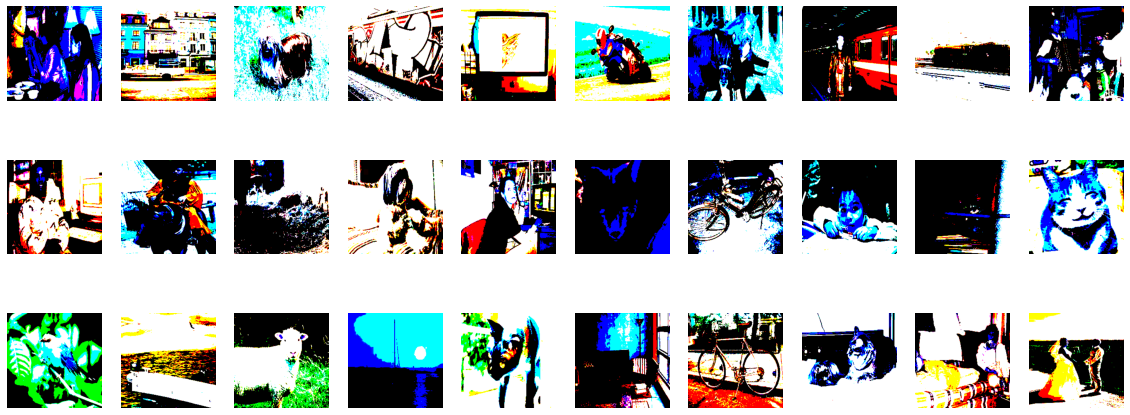

In [15]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### XAI: Predict Prototypes

In [16]:
# Load ResNet backbone
base_model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=False)

In [17]:
# Extract features of concept images with ResNet backbone
res_concepts = base_model.predict(concept_set.batch(32))
res_concepts = GlobalAveragePooling2D()(res_concepts)
tf.shape(res_concepts)

2024-04-11 15:01:32.756041: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-04-11 15:01:33.261214: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 15:01:33.261830: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 15:01:33.261851: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-04-11 15:01:33.262920: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-11 15:01:33.262958: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([  90, 2048], dtype=int32)>

In [18]:
con_rand_set = []
for img, _ in concept_set.as_numpy_iterator():
    con_rand_set.append(img)
con_rand_set = np.asarray(con_rand_set)
con_rand_set = np.concatenate((con_rand_set, random_dataset))
con_rand_set.shape

y_true_con_rand = np.concatenate((y_true_con, np.array([len(concepts)]*len(random_dataset))))
y_true_con_rand.shape

(1090,)

In [19]:
con_rand_set.shape

(1090, 224, 224, 3)

In [20]:
res_con_rand = base_model.predict(con_rand_set)
res_con_rand = GlobalAveragePooling2D()(res_con_rand)
tf.shape(res_con_rand)

<tf.Tensor: shape=(2,), dtype=int32, numpy=array([1090, 2048], dtype=int32)>

In [21]:
# Extract features for all samples
test_activations = GlobalAveragePooling2D()(base_model.predict(test_set.batch(32)))
test_activations.shape

TensorShape([212, 2048])

In [22]:
# Fit multiple kNNs for multiple random partitions of the random set
k = 8 # optimal k found in ResNet_Cluster_Concepts_Optim_k.ipynb
num_parts = 100 # how often to randomly select subsets of the random set
knn_probs = np.zeros((num_parts, len(test_activations), len(concepts)+1)) # tensor of probs for every sample and every concept
for i in range(num_parts):
    # Select random indexes (starting after last concept img index)
    random_ids = np.random.choice( np.arange(len(y_true_con), len(con_rand_set)), 30,
                                   replace = False)

    # Overall index vector (concept indexes, then current random subset indexes)
    con_rand_ids = np.concatenate( (np.arange(len(y_true_con)), random_ids) )

    # Fit a kNN on current partition
    neigh = KNeighborsClassifier(n_neighbors=k)
    neigh.fit(res_con_rand.numpy()[con_rand_ids], y_true_con_rand[con_rand_ids])

    # Predict concepts for all test vectors
    knn_probs[i] = neigh.predict_proba(test_activations)

In [23]:
knn_probs.shape

(100, 212, 4)

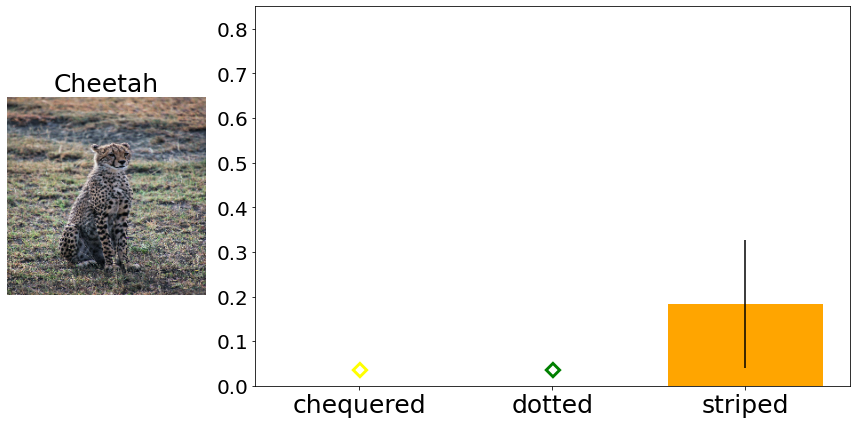

In [43]:
# Pick an example
ex_ind = 18
con_colors = ['yellow', 'green', 'orange']
for img_orig, lab in test_set_orig.skip(ex_ind).take(1): pass
img_orig = np.array(img_orig)/255.

# Compute means and stds of explanations
means = np.mean(knn_probs[:, ex_ind, :], axis=0)[:-1] # leave out random part
stds  = np.std(knn_probs[:, ex_ind, :],  axis=0)[:-1]

# Plot bars along with stds and explained image next to them
font_size = 25
f, (a0, a1) = plt.subplots(1, 2, gridspec_kw = {'width_ratios': [1, 3]}, figsize=(12, 6))

a0.imshow(img_orig)
a0.axis('off')
a0.set_title(classes[y_true_img[ex_ind]].capitalize(), size = font_size)

rects = a1.bar(range(len(concepts)), height = means, yerr = stds, color = con_colors)
# Add asterisks for zero-height bars
for i, (rect, height) in enumerate(zip(rects, means)):
   if height < 1e-3:
       a1.text(rect.get_x() + rect.get_width() / 2,
               height,  # Adjust vertical position slightly
               '$\diamond$', ha='center', va='bottom', fontsize=font_size+10, color=con_colors[i])

plt.xticks(range(len(concepts)), concepts, size = font_size)
plt.yticks(size = font_size-5)
plt.ylim(0.0, 0.85)

f.tight_layout()
f.savefig('./beexplainable/figures/copronn_std_1.png')

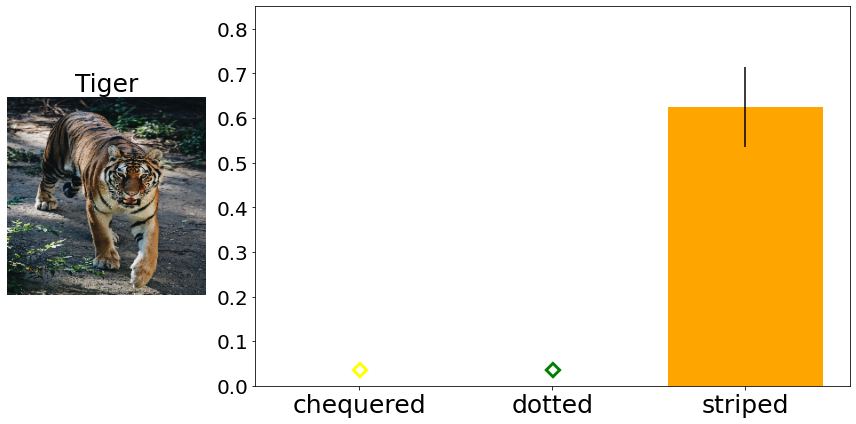

In [25]:
# Pick an example
ex_ind = 100
con_colors = ['yellow', 'green', 'orange']
for img_orig, lab in test_set_orig.skip(ex_ind).take(1): pass
img_orig = np.array(img_orig)/255.

# Compute means and stds of explanations
means = np.mean(knn_probs[:, ex_ind, :], axis=0)[:-1] # leave out random part
stds  = np.std(knn_probs[:, ex_ind, :],  axis=0)[:-1]

# Plot bars along with stds and explained image next to them
font_size = 25
f, (a0, a1) = plt.subplots(1, 2, gridspec_kw = {'width_ratios': [1, 3]}, figsize=(12, 6))

a0.imshow(img_orig)
a0.axis('off')
a0.set_title(classes[y_true_img[ex_ind]].capitalize(), size = font_size)

rects = a1.bar(range(len(concepts)), height = means, yerr = stds, color = con_colors)
# Add asterisks for zero-height bars
for i, (rect, height) in enumerate(zip(rects, means)):
   if height < 1e-3:
       a1.text(rect.get_x() + rect.get_width() / 2,
               height,  # Adjust vertical position slightly
               '$\diamond$', ha='center', va='bottom', fontsize=font_size+10, color=con_colors[i])

plt.xticks(range(len(concepts)), concepts, size = font_size)
plt.yticks(size = font_size-5)
plt.ylim(0.0, 0.85)

f.tight_layout()
f.savefig('./beexplainable/figures/copronn_std_2.png')